#DATA CLEANING

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
from pathlib import Path

Path.cwd()

WindowsPath('C:/Users/ravik')

In [4]:
data_folder = Path.cwd()

blinkit_files = {
    "customers": "blinkit_customers.csv",
    "customer_feedback": "blinkit_customer_feedback.csv",
    "delivery_performance": "blinkit_delivery_performance.csv",
    "inventory": "blinkit_inventory.csv",
    "inventory_new": "blinkit_inventoryNew.csv",
    "marketing_performance": "blinkit_marketing_performance.csv",
    "orders": "blinkit_orders.csv",
    "order_items": "blinkit_order_items.csv",
    "products": "blinkit_products.csv"
}

datasets = {
    name: pd.read_csv(data_folder / filename)
    for name, filename in blinkit_files.items()
}

In [5]:
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

customers: 2500 rows, 11 columns
customer_feedback: 5000 rows, 8 columns
delivery_performance: 5000 rows, 8 columns
inventory: 75172 rows, 4 columns
inventory_new: 18105 rows, 4 columns
marketing_performance: 5400 rows, 11 columns
orders: 5000 rows, 10 columns
order_items: 5000 rows, 4 columns
products: 268 rows, 10 columns


In [6]:
datasets["orders"].head()

,order_id,customer_id,order_date,promised_delivery_time,actual_delivery_time,delivery_status,order_total,payment_method,delivery_partner_id,store_id
0,1961864118,30065862,2024-07-17 08:34:01,2024-07-17 08:52:01,2024-07-17 08:47:01,On Time,3197.07,Cash,63230,4771
1,1549769649,9573071,2024-05-28 13:14:29,2024-05-28 13:25:29,2024-05-28 13:27:29,On Time,976.55,Cash,14983,7534
2,9185164487,45477575,2024-09-23 13:07:12,2024-09-23 13:25:12,2024-09-23 13:29:12,On Time,839.05,UPI,39859,9886
3,9644738826,88067569,2023-11-24 16:16:56,2023-11-24 16:34:56,2023-11-24 16:33:56,On Time,440.23,Card,61497,7917
4,5427684290,83298567,2023-11-20 05:00:39,2023-11-20 05:17:39,2023-11-20 05:18:39,On Time,2526.68,Cash,84315,2741


In [7]:
datasets["orders"].tail()

,order_id,customer_id,order_date,promised_delivery_time,actual_delivery_time,delivery_status,order_total,payment_method,delivery_partner_id,store_id
4995,1669690997,62600289,2023-12-25 15:46:20,2023-12-25 16:05:20,2023-12-25 16:10:20,On Time,1132.33,Cash,90914,1587
4996,8340761903,53640286,2023-11-27 09:18:43,2023-11-27 09:38:43,2023-11-27 09:36:43,On Time,2372.01,Cash,27952,3458
4997,5936301790,87059497,2024-06-21 19:09:09,2024-06-21 19:23:09,2024-06-21 19:26:09,On Time,3158.35,Cash,9590,7424
4998,5710579377,67310893,2024-06-06 14:58:13,2024-06-06 15:12:13,2024-06-06 15:10:13,On Time,1918.92,UPI,29940,6128
4999,2494813730,28663279,2023-08-23 12:04:18,2023-08-23 12:20:18,2023-08-23 12:21:18,On Time,1879.46,Card,32851,5588


In [8]:
datasets["orders"].columns.tolist()

['order_id',
 'customer_id',
 'order_date',
 'promised_delivery_time',
 'actual_delivery_time',
 'delivery_status',
 'order_total',
 'payment_method',
 'delivery_partner_id',
 'store_id']

# Exploratory Data Analysis(EDA)

In [10]:
datasets["orders"].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_id                5000 non-null   int64  
 1   customer_id             5000 non-null   int64  
 2   order_date              5000 non-null   object 
 3   promised_delivery_time  5000 non-null   object 
 4   actual_delivery_time    5000 non-null   object 
 5   delivery_status         5000 non-null   object 
 6   order_total             5000 non-null   float64
 7   payment_method          5000 non-null   object 
 8   delivery_partner_id     5000 non-null   int64  
 9   store_id                5000 non-null   int64  
dtypes: float64(1), int64(4), object(5)
memory usage: 390.8+ KB


In [10]:
datasets["orders"].isnull().sum()

order_id                  0
customer_id               0
order_date                0
promised_delivery_time    0
actual_delivery_time      0
delivery_status           0
order_total               0
payment_method            0
delivery_partner_id       0
store_id                  0
dtype: int64

In [11]:
datasets["orders"].duplicated().sum()

np.int64(0)

In [12]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

customers: 0 duplicate rows
customer_feedback: 0 duplicate rows
delivery_performance: 0 duplicate rows
inventory: 0 duplicate rows
inventory_new: 7359 duplicate rows
marketing_performance: 0 duplicate rows
orders: 0 duplicate rows
order_items: 0 duplicate rows
products: 0 duplicate rows


In [13]:
for name, df in datasets.items():
    print(f"{name}: {df.isnull().sum().sum()} missing values")

customers: 0 missing values
customer_feedback: 0 missing values
delivery_performance: 1902 missing values
inventory: 0 missing values
inventory_new: 0 missing values
marketing_performance: 0 missing values
orders: 0 missing values
order_items: 0 missing values
products: 0 missing values


In [14]:
for name, df in datasets.items():
    print(f"{name}: {df.shape}")

customers: (2500, 11)
customer_feedback: (5000, 8)
delivery_performance: (5000, 8)
inventory: (75172, 4)
inventory_new: (18105, 4)
marketing_performance: (5400, 11)
orders: (5000, 10)
order_items: (5000, 4)
products: (268, 10)


In [15]:
datasets["inventory_new"].head()

,product_id,date,stock_received,damaged_stock
0,153019,Mar-23,4,1
1,848226,Mar-23,4,1
2,965755,Mar-23,1,0
3,39154,Mar-23,4,0
4,34186,Mar-23,3,1


In [16]:
datasets["inventory_new"].duplicated().sum()

np.int64(7359)

In [17]:
datasets["inventory_new"].value_counts().head(10)

product_id  date    stock_received  damaged_stock
894539      Jul-23  1               0                6
473929      Jul-23  1               0                6
36412       Jul-23  1               0                6
578097      Jul-23  1               0                6
937542      Jul-23  1               0                6
891833      Jul-23  1               0                6
925482      Jul-23  1               0                6
306177      Jul-23  1               0                6
876139      Jul-23  1               0                6
623234      Jul-23  1               0                6
Name: count, dtype: int64

In [18]:
inventory = datasets["inventory_new"]

inventory[inventory.duplicated(keep=False)].sort_values(
    by=["product_id", "date"]
).head(10)

,product_id,date,stock_received,damaged_stock
858,4452,Apr-23,1,0
1433,4452,Apr-23,1,0
12427,4452,Apr-24,1,0
12563,4452,Apr-24,1,0
5071,4452,Aug-23,1,0
5362,4452,Aug-23,1,0
15613,4452,Aug-24,1,0
16143,4452,Aug-24,1,0
9253,4452,Dec-23,3,0
9556,4452,Dec-23,3,0


In [19]:
inventory[inventory.duplicated(keep=False)].head(10)

,product_id,date,stock_received,damaged_stock
11,888807,Mar-23,1,0
16,324809,Mar-23,1,0
21,990993,Mar-23,1,0
40,287070,Mar-23,1,0
46,677542,Mar-23,1,0
47,604184,Mar-23,1,0
59,661577,Mar-23,3,0
66,425341,Mar-23,1,0
72,818990,Mar-23,1,0
77,329351,Mar-23,3,0


In [20]:
inventory.duplicated(
    subset=["product_id", "date", "stock_received", "damaged_stock"]
).sum()

np.int64(7359)

In [21]:
inventory_clean = inventory.drop_duplicates().copy()

inventory_clean.shape

(10746, 4)

In [22]:
inventory_clean.duplicated().sum()


np.int64(0)

In [23]:
inventory_clean.isnull().sum()

product_id        0
date              0
stock_received    0
damaged_stock     0
dtype: int64

In [24]:
inventory_clean.dtypes

product_id         int64
date              object
stock_received     int64
damaged_stock      int64
dtype: object

In [25]:
inventory_clean["date"] = pd.to_datetime(
    inventory_clean["date"],
    format="%b-%y"
)

In [26]:
inventory_clean.dtypes

product_id                 int64
date              datetime64[ns]
stock_received             int64
damaged_stock              int64
dtype: object

In [27]:
datasets["customers"].isnull().sum()

customer_id          0
customer_name        0
email                0
phone                0
address              0
area                 0
pincode              0
registration_date    0
customer_segment     0
total_orders         0
avg_order_value      0
dtype: int64

In [28]:
datasets["customers"].duplicated().sum()

np.int64(0)

In [29]:
datasets["customer_feedback"].isnull().sum()

feedback_id          0
order_id             0
customer_id          0
rating               0
feedback_text        0
feedback_category    0
sentiment            0
feedback_date        0
dtype: int64

In [30]:
datasets["customer_feedback"].duplicated().sum()

np.int64(0)

In [31]:
datasets["delivery_performance"].isnull().sum()

order_id                    0
delivery_partner_id         0
promised_time               0
actual_time                 0
delivery_time_minutes       0
distance_km                 0
delivery_status             0
reasons_if_delayed       1902
dtype: int64

In [32]:
datasets["delivery_performance"]["delivery_status"].value_counts()

delivery_status
On Time                  3470
Slightly Delayed         1037
Significantly Delayed     493
Name: count, dtype: int64

In [33]:
datasets["delivery_performance"].groupby("delivery_status")["reasons_if_delayed"].apply(
    lambda x: x.isnull().sum()
)

delivery_status
On Time                  1902
Significantly Delayed       0
Slightly Delayed            0
Name: reasons_if_delayed, dtype: int64

In [34]:
datasets["delivery_performance"]["reasons_if_delayed"] = (
    datasets["delivery_performance"]["reasons_if_delayed"].fillna("No Delay")
)

In [35]:
datasets["delivery_performance"].duplicated().sum()

np.int64(0)

In [36]:
datasets["marketing_performance"].isnull().sum()

campaign_id          0
campaign_name        0
date                 0
target_audience      0
channel              0
impressions          0
clicks               0
conversions          0
spend                0
revenue_generated    0
roas                 0
dtype: int64

In [37]:
datasets["marketing_performance"].duplicated().sum()

np.int64(0)

In [38]:
datasets["orders"].isnull().sum()

order_id                  0
customer_id               0
order_date                0
promised_delivery_time    0
actual_delivery_time      0
delivery_status           0
order_total               0
payment_method            0
delivery_partner_id       0
store_id                  0
dtype: int64

In [39]:
datasets["orders"].duplicated().sum()

np.int64(0)

In [40]:
datasets["customers"].isnull().sum()

customer_id          0
customer_name        0
email                0
phone                0
address              0
area                 0
pincode              0
registration_date    0
customer_segment     0
total_orders         0
avg_order_value      0
dtype: int64

In [41]:
datasets["customers"].duplicated().sum()

np.int64(0)

In [42]:
for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"Dataset: {name}")
    print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
    print(f"Total missing values: {df.isnull().sum().sum()}")
    print(f"Duplicate rows: {df.duplicated().sum()}")
    print("\nMissing values by column:")
    print(df.isnull().sum())


Dataset: customers
Rows: 2500 | Columns: 11
Total missing values: 0
Duplicate rows: 0

Missing values by column:
customer_id          0
customer_name        0
email                0
phone                0
address              0
area                 0
pincode              0
registration_date    0
customer_segment     0
total_orders         0
avg_order_value      0
dtype: int64

Dataset: customer_feedback
Rows: 5000 | Columns: 8
Total missing values: 0
Duplicate rows: 0

Missing values by column:
feedback_id          0
order_id             0
customer_id          0
rating               0
feedback_text        0
feedback_category    0
sentiment            0
feedback_date        0
dtype: int64

Dataset: delivery_performance
Rows: 5000 | Columns: 8
Total missing values: 0
Duplicate rows: 0

Missing values by column:
order_id                 0
delivery_partner_id      0
promised_time            0
actual_time              0
delivery_time_minutes    0
distance_km              0
delivery_status 

In [43]:
# Blinkit Sales KPIs

orders = datasets["orders"]

total_orders = orders["order_id"].nunique()
total_revenue = orders["order_total"].sum()
average_order_value = orders["order_total"].mean()

print("BLINKIT SALES PERFORMANCE")
print("-" * 35)
print(f"Total Orders: {total_orders:,}")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")

BLINKIT SALES PERFORMANCE
-----------------------------------
Total Orders: 5,000
Total Revenue: ₹11,009,308.50
Average Order Value: ₹2,201.86


In [44]:
# Monthly Sales Analysis

orders["order_date"] = pd.to_datetime(orders["order_date"])

monthly_sales = (
    orders.groupby(orders["order_date"].dt.to_period("M"))
    .agg(
        Total_Orders=("order_id", "nunique"),
        Total_Revenue=("order_total", "sum")
    )
    .reset_index()
)

monthly_sales["order_date"] = monthly_sales["order_date"].astype(str)

monthly_sales

,order_date,Total_Orders,Total_Revenue
0,2023-03,120,272878.96
1,2023-04,238,554344.77
2,2023-05,276,608213.54
3,2023-06,232,505227.66
4,2023-07,244,567639.91
5,2023-08,285,623472.35
6,2023-09,262,571117.81
7,2023-10,254,578369.83
8,2023-11,265,567783.74
9,2023-12,268,615709.03


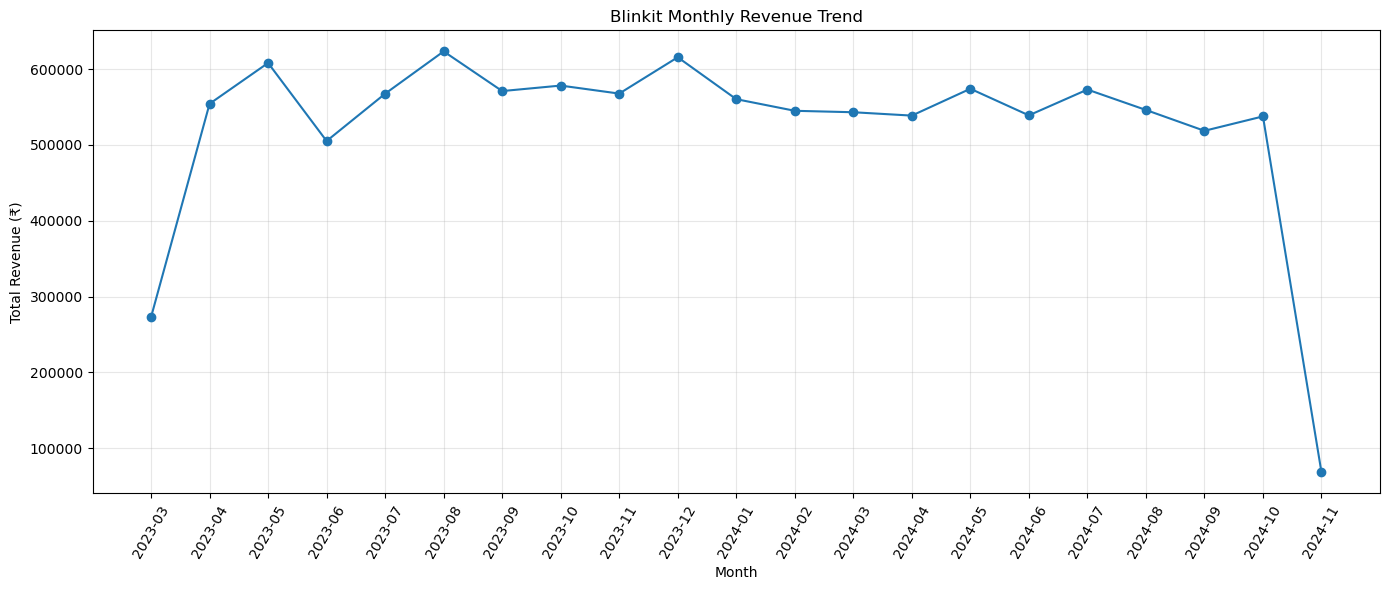

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["order_date"],
    monthly_sales["Total_Revenue"],
    marker="o"
)

plt.title("Blinkit Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
orders.columns.tolist()

['order_id',
 'customer_id',
 'order_date',
 'promised_delivery_time',
 'actual_delivery_time',
 'delivery_status',
 'order_total',
 'payment_method',
 'delivery_partner_id',
 'store_id']

In [47]:
# Blinkit Order Status Analysis

order_status = orders["delivery_status"].value_counts().reset_index()

order_status.columns = ["Delivery_Status", "Number_of_Orders"]

order_status["Percentage"] = (
    order_status["Number_of_Orders"] / len(orders) * 100
).round(2)

order_status

,Delivery_Status,Number_of_Orders,Percentage
0,On Time,3470,69.40
1,Slightly Delayed,1037,20.74
2,Significantly Delayed,493,9.86


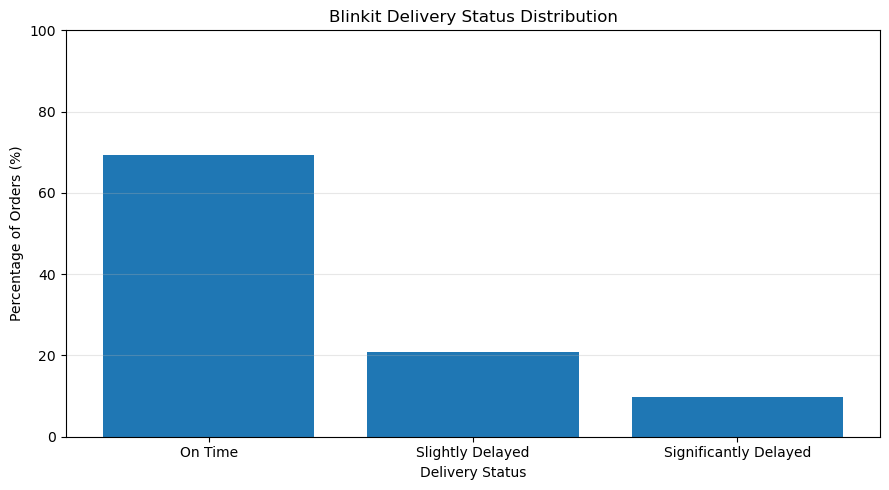

In [48]:
# Blinkit Delivery Status Distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    order_status["Delivery_Status"],
    order_status["Percentage"]
)

plt.title("Blinkit Delivery Status Distribution")
plt.xlabel("Delivery Status")
plt.ylabel("Percentage of Orders (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [49]:
# Blinkit Delivery Time Analysis

orders["promised_delivery_time"] = pd.to_datetime(
    orders["promised_delivery_time"]
)

orders["actual_delivery_time"] = pd.to_datetime(
    orders["actual_delivery_time"]
)

orders["delivery_duration_minutes"] = (
    orders["actual_delivery_time"] - orders["order_date"]
).dt.total_seconds() / 60

average_delivery_minutes = orders["delivery_duration_minutes"].mean()

print("BLINKIT DELIVERY PERFORMANCE")
print("-" * 35)
print(f"Average Delivery Duration: {average_delivery_minutes:.2f} minutes")

BLINKIT DELIVERY PERFORMANCE
-----------------------------------
Average Delivery Duration: 19.43 minutes


In [50]:
# Blinkit Promised vs Actual Delivery Analysis

orders["delivery_difference_minutes"] = (
    orders["actual_delivery_time"] - orders["promised_delivery_time"]
).dt.total_seconds() / 60

average_delay = orders["delivery_difference_minutes"].mean()

print("PROMISED VS ACTUAL DELIVERY")
print("-" * 35)
print(f"Average Difference: {average_delay:.2f} minutes")
print(f"Orders Early: {(orders['delivery_difference_minutes'] < 0).sum()}")
print(f"Orders On Time: {(orders['delivery_difference_minutes'] == 0).sum()}")
print(f"Orders Late: {(orders['delivery_difference_minutes'] > 0).sum()}")


PROMISED VS ACTUAL DELIVERY
-----------------------------------
Average Difference: 4.44 minutes
Orders Early: 1563
Orders On Time: 339
Orders Late: 3098


In [51]:
# Blinkit Customer KPIs

total_customers = orders["customer_id"].nunique()

orders_per_customer = (
    orders.groupby("customer_id")["order_id"]
    .nunique()
)

repeat_customers = (orders_per_customer > 1).sum()

print("BLINKIT CUSTOMER ANALYSIS")
print("-" * 35)
print(f"Unique Customers: {total_customers:,}")
print(f"Repeat Customers: {repeat_customers:,}")
print(
    f"Repeat Customer Rate: "
    f"{repeat_customers / total_customers * 100:.2f}%"
)

BLINKIT CUSTOMER ANALYSIS
-----------------------------------
Unique Customers: 2,172
Repeat Customers: 1,492
Repeat Customer Rate: 68.69%


In [52]:
# Blinkit Payment Method Analysis

payment_analysis = (
    orders.groupby("payment_method")
    .agg(
        Total_Orders=("order_id", "nunique"),
        Total_Revenue=("order_total", "sum")
    )
    .reset_index()
)

payment_analysis["Revenue_Percentage"] = (
    payment_analysis["Total_Revenue"]
    / payment_analysis["Total_Revenue"].sum() * 100
).round(2)

payment_analysis["Total_Revenue"] = (
    payment_analysis["Total_Revenue"].round(2)
)

print("BLINKIT PAYMENT METHOD ANALYSIS")
print("-" * 40)

payment_analysis


BLINKIT PAYMENT METHOD ANALYSIS
----------------------------------------


,payment_method,Total_Orders,Total_Revenue,Revenue_Percentage
0,Card,1285,2865557.53,26.03
1,Cash,1257,2770463.99,25.16
2,UPI,1214,2658282.71,24.15
3,Wallet,1244,2715004.27,24.66


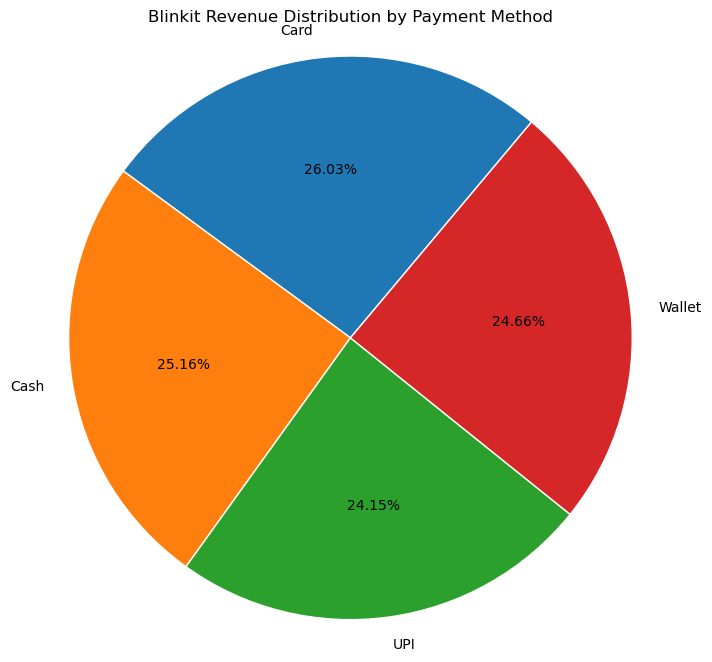

In [55]:
# Payment Method Revenue Distribution

import matplotlib.pyplot as plt



plt.figure(figsize=(8, 8))

plt.pie(
    payment_analysis["Total_Revenue"],
    labels=payment_analysis["payment_method"],
    autopct="%1.2f%%",
    startangle=50,
    wedgeprops={"edgecolor": "white"}
)

plt.title("Blinkit Revenue Distribution by Payment Method")
plt.axis("equal")
plt.show()


In [56]:
# Inspect Product Dataset

print("Available datasets:")
print(datasets.keys())

print("\nProduct dataset columns:")
print(datasets["products"].columns.tolist())

print("\nFirst 5 rows:")
datasets["products"].head()


Available datasets:
dict_keys(['customers', 'customer_feedback', 'delivery_performance', 'inventory', 'inventory_new', 'marketing_performance', 'orders', 'order_items', 'products'])

Product dataset columns:
['product_id', 'product_name', 'category', 'brand', 'price', 'mrp', 'margin_percentage', 'shelf_life_days', 'min_stock_level', 'max_stock_level']

First 5 rows:


,product_id,product_name,category,brand,price,mrp,margin_percentage,shelf_life_days,min_stock_level,max_stock_level
0,153019,Onions,Fruits & Vegetables,Aurora LLC,947.95,1263.93,25.0,3,13,88
1,11422,Potatoes,Fruits & Vegetables,Ramaswamy-Tata,127.16,169.55,25.0,3,20,65
2,669378,Potatoes,Fruits & Vegetables,Chadha and Sons,212.14,282.85,25.0,3,23,70
3,848226,Tomatoes,Fruits & Vegetables,Barad and Sons,209.59,279.45,25.0,3,10,51
4,890623,Onions,Fruits & Vegetables,"Sangha, Nagar and Varty",354.52,472.69,25.0,3,27,55


In [57]:
# Blinkit Product Category Analysis

products = datasets["products"]

category_analysis = (
    products.groupby("category")
    .agg(
        Total_Products=("product_id", "nunique"),
        Average_Price=("price", "mean"),
        Average_Margin=("margin_percentage", "mean")
    )
    .reset_index()
)

category_analysis["Average_Price"] = (
    category_analysis["Average_Price"].round(2)
)

category_analysis["Average_Margin"] = (
    category_analysis["Average_Margin"].round(2)
)

category_analysis = category_analysis.sort_values(
    "Total_Products", ascending=False
)

print("BLINKIT PRODUCT CATEGORY ANALYSIS")
print("-" * 40)

category_analysis


BLINKIT PRODUCT CATEGORY ANALYSIS
----------------------------------------


,category,Total_Products,Average_Price,Average_Margin
2,Dairy & Breakfast,30,569.10,20.0
3,Fruits & Vegetables,27,546.54,25.0
5,Household Care,27,403.19,25.0
10,Snacks & Munchies,27,417.11,35.0
7,Personal Care,25,441.60,35.0
8,Pet Care,25,546.93,35.0
9,Pharmacy,25,599.03,20.0
4,Grocery & Staples,24,397.36,15.0
1,Cold Drinks & Juices,22,500.52,30.0
6,Instant & Frozen Food,20,420.34,40.0


In [59]:
# Inspect Order Items Dataset

order_items = datasets["order_items"]

print("ORDER ITEMS DATASET")
print("-" * 35)

print("Shape:", order_items.shape)
print("\nColumns:")
print(order_items.columns.tolist())

print("\nFirst 5 rows:")
order_items.head()


ORDER ITEMS DATASET
-----------------------------------
Shape: (5000, 4)

Columns:
['order_id', 'product_id', 'quantity', 'unit_price']

First 5 rows:


,order_id,product_id,quantity,unit_price
0,1961864118,642612,3,517.03
1,1549769649,378676,1,881.42
2,9185164487,741341,2,923.84
3,9644738826,561860,1,874.78
4,5427684290,602241,2,976.55


In [61]:
# Top 10 products sold in the blinkit 
top_10_products = (
    datasets["order_items"]
    .groupby("product_id")["quantity"]
    .sum()
    .nlargest(10)
    .reset_index(name="Total_Quantity_Sold")
    .merge(
        datasets["products"][["product_id", "product_name"]],
        on="product_id",
        how="left"
    )
)

top_10_products


,product_id,Total_Quantity_Sold,product_name
0,51036,70,Baby Food
1,820973,68,Baby Wipes
2,604184,62,Toilet Cleaner
3,34186,61,Mangoes
4,992178,60,Pain Reliever
5,880510,58,Bread
6,89084,56,Milk
7,673058,56,Cough Syrup
8,123983,55,Cough Syrup
9,557908,55,Vitamins


In [62]:
datasets["customer_feedback"].head()


,feedback_id,order_id,customer_id,rating,feedback_text,feedback_category,sentiment,feedback_date
0,2234710,1961864118,30065862,4,"It was okay, nothing special.",Delivery,Neutral,2024-07-17
1,5450964,1549769649,9573071,3,The order was incorrect.,App Experience,Negative,2024-05-28
2,482108,9185164487,45477575,3,"It was okay, nothing special.",App Experience,Neutral,2024-09-23
3,4823104,9644738826,88067569,4,The product met my expectations.,App Experience,Neutral,2023-11-24
4,3537464,5427684290,83298567,3,Product was damaged during delivery.,Delivery,Negative,2023-11-20


In [63]:
datasets["customer_feedback"]["sentiment"].value_counts()


sentiment
Neutral     1738
Negative    1642
Positive    1620
Name: count, dtype: int64

In [64]:
datasets["customer_feedback"].query(
    "sentiment == 'Negative'"
)["feedback_category"].value_counts()


feedback_category
Product Quality     432
Customer Service    417
Delivery            405
App Experience      388
Name: count, dtype: int64

In [65]:
# Average Customer Rating by Feedback Category

feedback = datasets["customer_feedback"]

feedback.groupby("feedback_category")["rating"].mean().round(2).sort_values()


feedback_category
Product Quality     3.32
Delivery            3.33
App Experience      3.36
Customer Service    3.37
Name: rating, dtype: float64

In [66]:

datasets["inventory"].columns.tolist(), datasets["inventory"].head()


(['product_id', 'date', 'stock_received', 'damaged_stock'],
    product_id        date  stock_received  damaged_stock
 0      153019  17-03-2023               4              2
 1      848226  17-03-2023               4              2
 2      965755  17-03-2023               1              0
 3       39154  17-03-2023               4              0
 4       34186  17-03-2023               3              2)

In [67]:
# Inventory Analysis: Net Stock Received by Product

inventory = datasets["inventory"]

inventory_summary = (
    inventory.groupby("product_id")
    .agg(
        Total_Received=("stock_received", "sum"),
        Total_Damaged=("damaged_stock", "sum")
    )
)

inventory_summary["Net_Stock_Received"] = (
    inventory_summary["Total_Received"]
    - inventory_summary["Total_Damaged"]
)

inventory_summary.sort_values(
    "Net_Stock_Received", ascending=False
).head(10)


,Total_Received,Total_Damaged,Net_Stock_Received
product_id,,,
490602,898,300,598
903336,832,272,560
287070,837,280,557
760684,849,304,545
120532,813,276,537
274207,800,286,514
937542,801,290,511
837480,759,262,497
52729,755,264,491


In [68]:
# Inventory Damage Rate by Product

inventory_summary["Damage_Rate_Percent"] = (
    inventory_summary["Total_Damaged"]
    / inventory_summary["Total_Received"] * 100
).round(2)

inventory_summary.sort_values(
    "Damage_Rate_Percent", ascending=False
).head(10)


,Total_Received,Total_Damaged,Net_Stock_Received,Damage_Rate_Percent
product_id,,,,
709916,295,324,-29,109.83
448752,292,300,-8,102.74
767398,330,338,-8,102.42
897083,314,300,14,95.54
739534,318,298,20,93.71
739448,343,318,25,92.71
473647,333,308,25,92.49
133542,327,296,31,90.52
9436,322,286,36,88.82


In [69]:
# Inventory Data Quality Check

print("Total Stock Received:", inventory["stock_received"].sum())
print("Total Damaged Stock:", inventory["damaged_stock"].sum())
print("Rows Where Damaged Exceeds Received:",
      (inventory["damaged_stock"] > inventory["stock_received"]).sum())


Total Stock Received: 147526
Total Damaged Stock: 80268
Rows Where Damaged Exceeds Received: 29255


In [70]:

inventory["date"] = pd.to_datetime(
    inventory["date"], dayfirst=True, errors="coerce"
)

print("Start Date:", inventory["date"].min())
print("End Date:", inventory["date"].max())
print("Missing/Invalid Dates:", inventory["date"].isna().sum())


Start Date: 2023-03-17 00:00:00
End Date: 2024-11-05 00:00:00
Missing/Invalid Dates: 0


In [71]:
# Final Data Quality Summary

for name, df in datasets.items():
    print(
        f"{name:25} | "
        f"Rows: {len(df):6} | "
        f"Missing: {df.isna().sum().sum():5} | "
        f"Duplicate rows: {df.duplicated().sum():5}"
    )


customers                 | Rows:   2500 | Missing:     0 | Duplicate rows:     0
customer_feedback         | Rows:   5000 | Missing:     0 | Duplicate rows:     0
delivery_performance      | Rows:   5000 | Missing:     0 | Duplicate rows:     0
inventory                 | Rows:  75172 | Missing:     0 | Duplicate rows:     0
inventory_new             | Rows:  18105 | Missing:     0 | Duplicate rows:  7359
marketing_performance     | Rows:   5400 | Missing:     0 | Duplicate rows:     0
orders                    | Rows:   5000 | Missing:     0 | Duplicate rows:     0
order_items               | Rows:   5000 | Missing:     0 | Duplicate rows:     0
products                  | Rows:    268 | Missing:     0 | Duplicate rows:     0


In [72]:
# Blinkit Business Intelligence Project — Python Summary

print("=" * 55)
print("BLINKIT BUSINESS INTELLIGENCE & INSIGHTS")
print("PYTHON ANALYSIS SUMMARY")
print("=" * 55)

print(f"Total Orders: {total_orders:,}")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Unique Customers: {total_customers:,}")
print(f"Repeat Customers: {repeat_customers:,}")
print(f"Repeat Customer Rate: {repeat_customers / total_customers * 100:.2f}%")

print("\nCustomer Sentiment:")
print(datasets["customer_feedback"]["sentiment"].value_counts())

print("\nInventory Data Limitation:")
print("Historical damaged-stock records exceed stock received")
print("in some rows; current stock on hand cannot be inferred")
print("from the available inventory columns alone.")

print("\nPython analysis summary completed.")


BLINKIT BUSINESS INTELLIGENCE & INSIGHTS
PYTHON ANALYSIS SUMMARY
Total Orders: 5,000
Total Revenue: ₹11,009,308.50
Average Order Value: ₹2,201.86
Unique Customers: 2,172
Repeat Customers: 1,492
Repeat Customer Rate: 68.69%

Customer Sentiment:
sentiment
Neutral     1738
Negative    1642
Positive    1620
Name: count, dtype: int64

Inventory Data Limitation:
Historical damaged-stock records exceed stock received
in some rows; current stock on hand cannot be inferred
from the available inventory columns alone.

Python analysis summary completed.
